# Методы бинарной классификации 

На сегодняшнем семинаре рассмотрим методы, позволяющие решать задачу бинарной классфикации: т.е. распределять объекты по двум группам. Мы рассмотрим такие модели, как: 

- Дерерья решений (Decision Tree)
- Случайные леса (Random Forest) 
- Метод опорных векторов (SVM) 
- Логистическая регрессия (Logistic Regression)
- Метод ближайщего соседа (KNN) 
- Нейронные сети (Neural Networks) 


Научимся оценивать качество моделей, используя такие метрики как: 

- Accuracy 
- Recall
- Precison 
- F-statistics 
- ROC-AUC

Полезная статья: https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html#sphx-glr-auto-examples-classification-plot-classifier-comparison-py

## Подготовка 

In [1]:
 #import libraries
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import sklearn

In [2]:
df = pd.read_csv('YPS.csv') 
df = df.dropna()

In [3]:
#calculate body mass index 
df["BMI"] = (df["Weight"]/((df["Height"]*0.01)**2))

#calculate binary obesity variable (if a person has obesity)
Obesity = []
for i in df['BMI']:
    if i >= 25:
        Obesity.append('Overweight')
    else:
        Obesity.append('Normal')
df['Obesity_status'] = Obesity

## I. Деревья решений

Дерево решений в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

### Пример 1. Определение людей с лишним весом по BMI 

Мы с вами знаем, что переменная Obesity_status была создана по следующему правилу: если BMI меньше либо равен 25, то у человека лишний вес. Но модель не знает, как мы создавали Obesity_status. Проверим, сможет ли она восстановить наше правило, обучившись на данных! 

Создадим датасет, в котором будет переменная, которую мы хотим предсказывать, и переменные, которые модель может использовать для предсказания. 

Поместим в датасет "правильную" переменную-предиктор ("BMI") и "неправильную" переменную предиктор ("Age"), чтобы проверить, разберется ли модель, какая переменная ей нужна

In [4]:
df1 = df[['BMI', 'Age', 'Obesity_status']]   #датасет для примера 1
X = df1[['BMI', 'Age']]    # X - переменные, основываясь на которых модель делает предсказания (features)
y = df1['Obesity_status']  # y - переменная, которую модель должна предсказывать 

Иллюстрация для наглядности. Дерево должно провести горизонтальную линию по BMI = 25

<AxesSubplot:xlabel='Obesity_status', ylabel='BMI'>

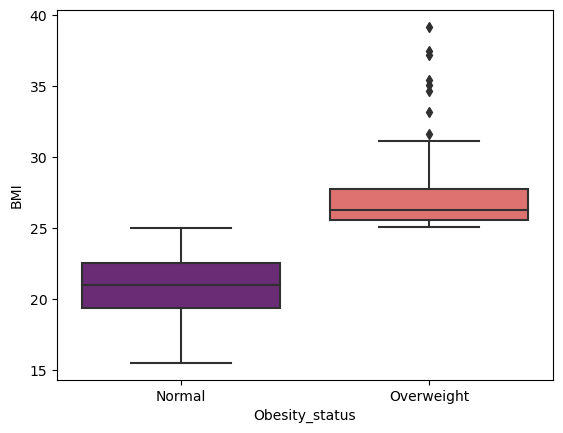

In [232]:
sns.boxplot(data = df, y = 'BMI', x = 'Obesity_status', palette = "magma")

Создадим тестовую и тренировочную выборку с помощью train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y)

Построим модель с параметрами по умолчанию 

In [6]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [7]:
clf.predict(X_train)

array(['Normal', 'Normal', 'Normal', 'Overweight', 'Normal', 'Normal',
       'Normal', 'Normal', 'Overweight', 'Normal', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Overweight', 'Normal', 'Normal',
       'Normal', 'Normal', 'Overweight', 'Overweight', 'Normal',
       'Overweight', 'Normal', 'Normal', 'Normal', 'Normal', 'Overweight',
       'Normal', 'Normal', 'Overweight', 'Normal', 'Overweight', 'Normal',
       'Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Normal',
       'Overweight', 'Normal', 'Normal', 'Normal', 'Normal', 'Normal',
       'Overweight', 'Normal', 'Normal', 'Normal', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Overweight', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Overweight', 'Normal', 'Normal',
       'Normal', 'Ov

Посмотрим точность модели на тренировочной выборке. Она оказалась идеальной! 

In [8]:
clf.score(X_train, y_train)

1.0

С тестовой выборкой дерево тоже отлично справляется

In [9]:
clf.score(X_test, y_test)

1.0

Посмотрим, каким правилом руководствутся модель. Она практически точно поняла наше правило!

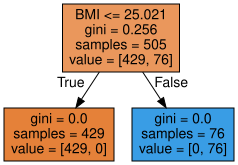

In [10]:
from sklearn.tree import export_graphviz
from IPython.display import SVG
from graphviz import Source
from sklearn import tree
Source(tree.export_graphviz(clf, out_file=None, feature_names=X.columns))
graph = Source(tree.export_graphviz(clf, out_file=None, feature_names=X.columns, filled=True))
SVG(graph.pipe(format='svg'))

### Пример 2. Определение людей с лишним весом по росту и весу 

Теперь усложним дереву задачу. Мы помним, что BMI рассчитан по формуле на основе роста и веса. По сути, это мера соотношения роста и веса. Посмотрим, сможет ли модель воссоздать нашу логику и определить, есть ли у человека лишний вес, основываясь на данных по росту и весу.

По графику мы видим, что чтобы поделить людей на классы, нужно провести косую черту 

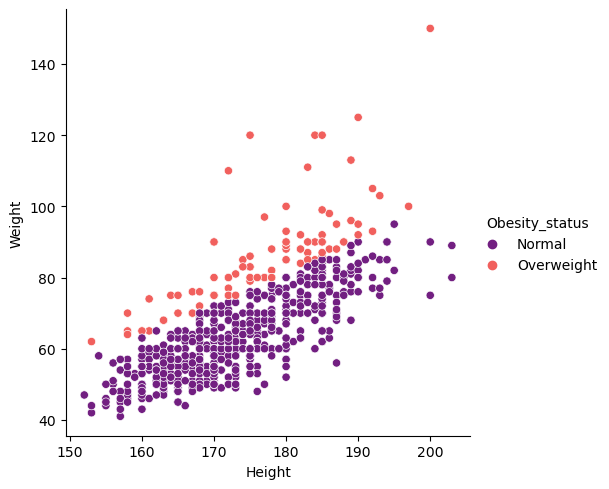

In [238]:
sns.relplot(data=df, x="Height", y="Weight", hue="Obesity_status", palette = "magma")

In [11]:
df2 = df[['Height', 'Weight', 'Obesity_status']]
X = df2[['Height', 'Weight']]
y = df2['Obesity_status']
X_train, X_test, y_train, y_test = train_test_split(X, y)
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)
clf.score(X_train, y_train)

1.0

На тренировочной выборке модель справляется так же хорошо, а вот на тестовой показывает результат хуже. Похоже, модель переобучена

In [12]:
clf.score(X_test, y_test)

0.9704142011834319

Посмотрим, какой логике придерживалось дерево. 

Мы видим, что в каждом узле дерево делит либо по росту, либо по весу. Оно не способно объединить переменные. Скорее всего, на специфичной выборке алгоритм, который нашло дерево, окажется провальным. Таким образом, данный алгоритм не справляется с задачей, которая для человека является тривиальной. 

**Вывод**: Не стоит использовать дерево решений, если предполагается существенное взаимодействие между двумя интервальными предикторами

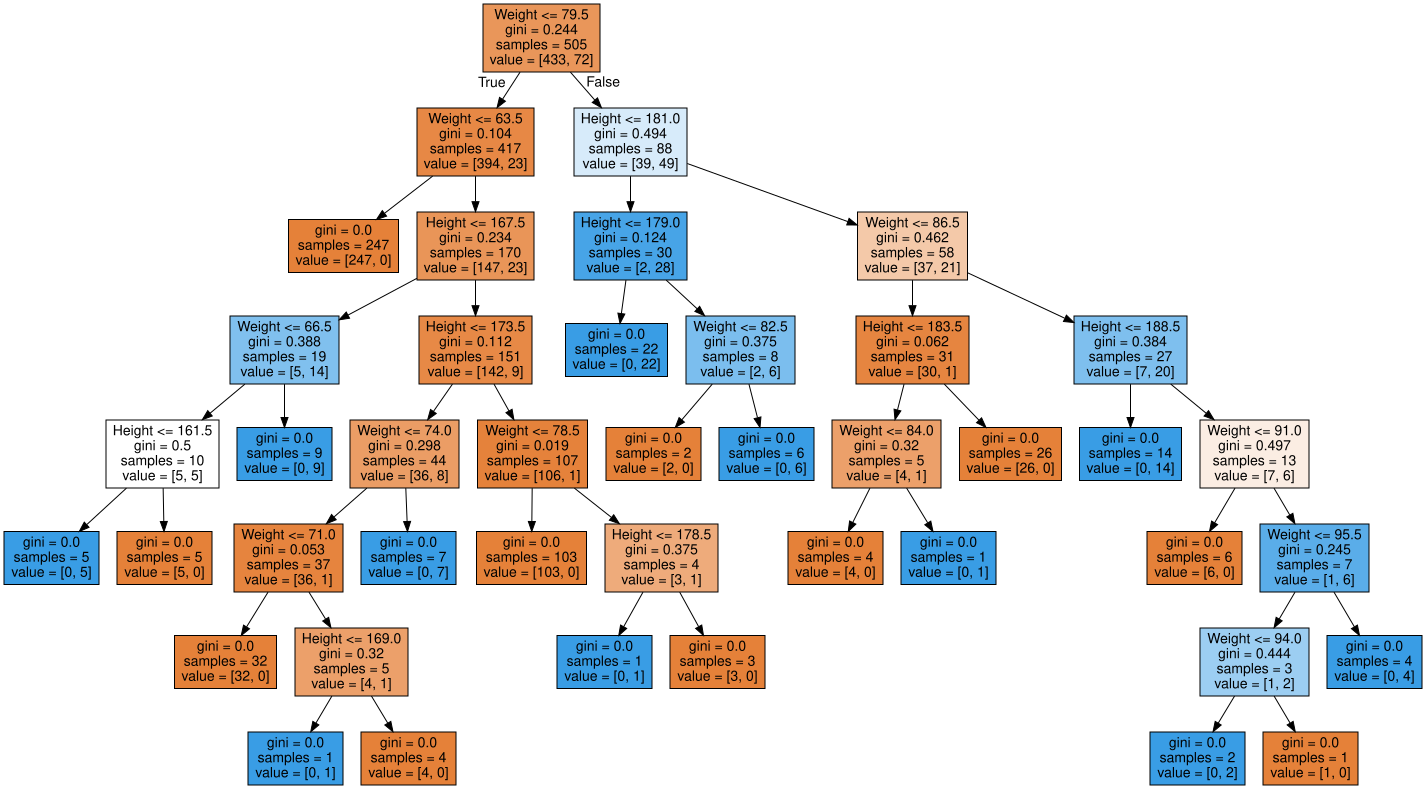

In [13]:
from sklearn.tree import export_graphviz
from IPython.display import SVG
from graphviz import Source
from sklearn import tree
Source(tree.export_graphviz(clf, out_file=None, feature_names=X.columns))
graph = Source(tree.export_graphviz(clf, out_file=None, feature_names=X.columns, filled=True))
SVG(graph.pipe(format='svg'))

Вместо того, чтобы провести одну косую черту, дерево делит пространство на прямоугольники

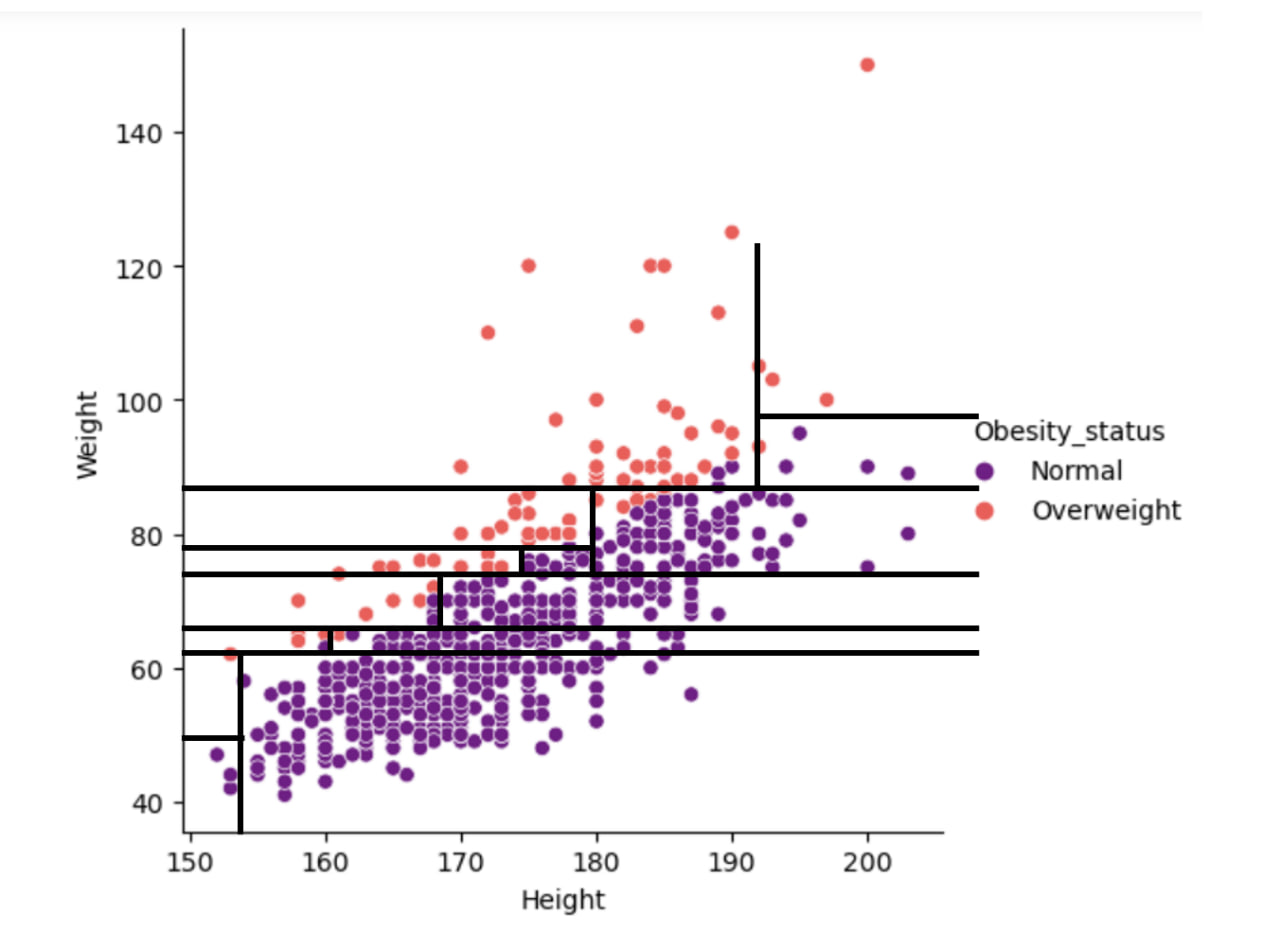

### Пример 3. Предсказание лишнего веса по образу жизни 

В прошлых примерах мы наблюдали, как модель справляется с заданиями, для которых мы заранее знаем оптимальную стратегию решения. Сейчас посмотрим, как модель справится с настоящим исследовательским вопросом - как лишний вес связан с образом жизни.

Заменим текстовые обозначения категориальных переменных числовыми. Это нужно для того, чтобы выводить метрики качества модели (они не работают с текстовыми переменными) 

In [14]:
df['Gender_num'] = np.where(df['Gender'] == 'male', 0, 1)
df['Edu_num'] = np.where(df['Education'] == ' college/bachelor degree', 1, 0)
df['Village_num'] = np.where(df['Village - town'] == 'city', 1, 0)
df['Alco_num']  = np.where(df['Alcohol'] == 'drink a lot', 1, 0)
df['Obesity_num'] = np.where(df['Obesity_status'] == 'Overweight', 1, 0)

Подготовим обучающую и тестовую выборки

In [15]:
df3 = df[['Internet', 'PC', 'Age', 'Gender_num', 'Edu_num', 'Village_num', 'Spending on healthy eating', 'Spending on looks', 'Happiness in life', 'Health', 'Active sport', 'Adrenaline sports', 'Alco_num', 'Healthy eating', 'Eating to survive', 'Self-criticism', 'Obesity_num']]
X = df[['Internet', 'PC', 'Age', 'Gender_num', 'Edu_num', 'Village_num', 'Spending on healthy eating', 'Spending on looks', 'Happiness in life', 'Health', 'Active sport', 'Adrenaline sports', 'Alco_num', 'Healthy eating', 'Eating to survive', 'Self-criticism']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)

Обучим модель и посмотрим, как она предсказывает на тренировочной и тестовой выбооках 

In [16]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)
clf.score(X_train, y_train)

1.0

На тестовой выборке модель справляется гораздо хуже, чем на тренировочной. Это явный признак переобученности

In [21]:
clf.score(X_test, y_test)

0.7751479289940828

Скорее всего, наше дерево слишком "разрослось". Чтобы этого избежать, стоит задать ограничивающие парамерты. Но как их выбрать? 
Для этого в Sklearn есть полезный инструмент GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

Он перебирает варианты с разными параметрами и возвращает тот, который дает максимум accuracy score на тестовой выборке. GridSearchCV можно применять ко всем моделям бинарной классификации

In [255]:
from sklearn.model_selection import GridSearchCV

#создаем словарь с параметрами, которые будет перебирать GridSearchCV
parameters = {'criterion':('gini', 'entropy'), 'max_depth':range (2, 10), 'min_samples_split':range (2, 10), 'ccp_alpha': [0, 0.01, 0.1, 0.5], 'min_samples_leaf': range(1, 10)}
clf = DecisionTreeClassifier() #наша модель - дерево решений 
grid = GridSearchCV(clf, parameters) #по очереди применям все параметры к модели
grid.fit(X_train, y_train)  #смотрим, как модель работает на тренировочной выборке
grid.best_params_  #выводим параметры модели, которые принесли лучший результат на тренировочной выборке 

{'ccp_alpha': 0,
 'criterion': 'entropy',
 'max_depth': 2,
 'min_samples_leaf': 1,
 'min_samples_split': 2}

Построим модель с лучшими параметрами 

In [22]:
clf = DecisionTreeClassifier(criterion = 'entropy', max_depth =2)
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.8757396449704142

Посмотрим, какой логики придерживается дерево. Что вы можете сказать про данную модель? Справляется ли она со своей задачей? Почему? 

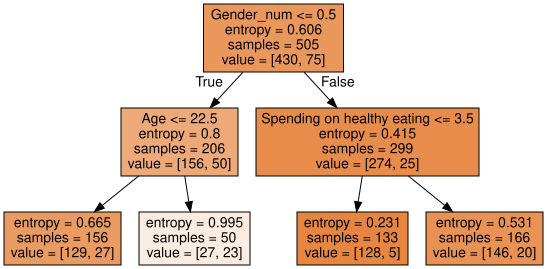

In [23]:
from sklearn.tree import export_graphviz
from IPython.display import SVG
from graphviz import Source
from sklearn import tree
Source(tree.export_graphviz(clf, out_file=None, feature_names=X.columns))
graph = Source(tree.export_graphviz(clf, out_file=None, feature_names=X.columns, filled=True))
SVG(graph.pipe(format='svg'))

#### Метрики качества модели

*Матрица путаницы* 

In [24]:
from sklearn.metrics import confusion_matrix

y_pred = clf.predict(X_test) #предсказания модели на тестовой выборке
confusion_matrix(y_test, y_pred)  #в confusion_matrix передаем правильные ответы (y_test) и предсказания модели

array([[148,   0],
       [ 21,   0]], dtype=int64)

Чтобы не запутаться, какое число чему соответствует:

In [25]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(tn, fp, fn, tp)

148 0 21 0


Как правило, матрица путаницы сама по себе нам не нужна. При оценке качества модели можно сразу переходить к Recall, Precision, F-score. Эти метрики автоматически рассчитываются на основе матрицы путаницы 

*Recall, Precision, F-score*

Что вы можете сказать, глядя на метрики качества? 

In [26]:
from sklearn.metrics import classification_report
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       0.88      1.00      0.93       148
  Overweight       0.00      0.00      0.00        21

    accuracy                           0.88       169
   macro avg       0.44      0.50      0.47       169
weighted avg       0.77      0.88      0.82       169



C:\Users\user\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1327: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\user\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1327: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\user\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1327: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


*ROC-кривая, AUC*

In [1]:
from sklearn.metrics import roc_curve
import numpy as np
import matplotlib.pyplot as plt


fpr, tpr, thresholds = roc_curve(y_test, y_pred, pos_label = 1)

# Print ROC curve
plt.plot(fpr,tpr)
plt.show() 

# Print AUC
auc = np.trapz(tpr,fpr)
print('AUC:', auc)

NameError: name 'y_test' is not defined

**Общий вывод**: модель не способна определять людей с лишим весом на основе данных об их образе жизни 

## II. Случайный лес 

Случайный лес в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

Случайный лес - это несколько деревьев решений, каждое из которых обучается на своей части датасета. Потом предсказания всех деревьев усредняются. Случайный лес помогает избежать переобученности - проблемы, которой подвержены деревья решений

Посмотрим, справится ли случайный лес с предсказанием лишнего веса по образу жизни (Пример 3 из прошлого раздела)  

In [28]:
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=15, max_depth=2, min_samples_leaf = 9, min_samples_split = 5)
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.8757396449704142

Мы не можем визуализировать случайный лес, как визуализировали дерево решений, но можем посмотреть, на какие предикторы опиралась модель

In [29]:
clf.feature_importances_  #значимость каждого предиктора 

array([0.20869476, 0.04920917, 0.22579155, 0.13912279, 0.        ,
       0.        , 0.08108405, 0.        , 0.05671885, 0.0816347 ,
       0.00550975, 0.        , 0.02410056, 0.00574797, 0.02675858,
       0.09562726])

In [263]:
clf.feature_names_in_  #название каждого предиктора 

array(['Internet', 'PC', 'Age', 'Gender_num', 'Edu_num', 'Village_num',
       'Spending on healthy eating', 'Spending on looks',
       'Happiness in life', 'Health', 'Active sport', 'Adrenaline sports',
       'Alco_num', 'Healthy eating', 'Eating to survive',
       'Self-criticism'], dtype=object)

Чтобы не запутаться, создадим датафрейм со значимостью и названием каждого предиктора и отсортируем его по значимости в порядке убывания (самые важные переменные сверху)

In [30]:
features = pd.DataFrame({'importance': clf.feature_importances_, 'name': clf.feature_names_in_}, columns=['importance', 'name'])
features.sort_values(by=['importance'], ascending=False)

,importance,name
2,0.225792,Age
0,0.208695,Internet
3,0.139123,Gender_num
15,0.095627,Self-criticism
9,0.081635,Health
6,0.081084,Spending on healthy eating
8,0.056719,Happiness in life
1,0.049209,PC
14,0.026759,Eating to survive
12,0.024101,Alco_num


## III. Метод опорных векторов

Метод опорных векторов в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

Метод опорных векторов использует принципиально иной принцип классфикации, по сравнению с деревом решений. Посмотрим, как он справится с задачей предсказания ожирения по росту и весу (Пример 2) - задачей, которую дерево решает далеко не самым оптимальным путем.

In [31]:
X = df[['Height', 'Weight']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)

Переведем X_train, X_test, y_train, y_test в формат numpy. Это нужно для дальнейшей визуализации

In [32]:
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

Построим модель и посмотрим, как она справляется с предсказанием на тестовой выборке 

In [33]:
from sklearn.svm import SVC
clf = SVC(kernel='linear')
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.9940828402366864

Визуализируем решение модели. Мы видим, что данный алгоритм нашел оптимальный способ классификации

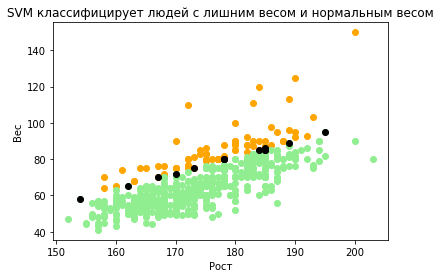

In [34]:
support_vectors = clf.support_vectors_

plt.scatter(X_train[y_train == 1,0], X_train[y_train == 1, 1], c='orange')
plt.scatter(X_train[y_train == 0,0], X_train[y_train == 0, 1], c='lightgreen')
plt.scatter(support_vectors[:,0], support_vectors[:,1], c = 'black')

plt.title('SVM классифицирует людей с лишним весом и нормальным весом')
plt.xlabel('Рост')
plt.ylabel('Вес')
plt.show()

#### Метрики качества модели

In [35]:
y_pred = clf.predict(X_test)
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       146
  Overweight       0.96      1.00      0.98        23

    accuracy                           0.99       169
   macro avg       0.98      1.00      0.99       169
weighted avg       0.99      0.99      0.99       169



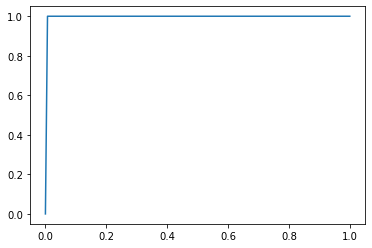

AUC: 0.9965753424657534


In [36]:
from sklearn.metrics import roc_curve
import numpy as np
import matplotlib.pyplot as plt


fpr, tpr, thresholds = roc_curve(y_test, y_pred, pos_label = 1)

# Print ROC curve
plt.plot(fpr,tpr)
plt.show() 

# Print AUC
auc = np.trapz(tpr,fpr)
print('AUC:', auc)

## IV. Логистическая регрессия

Логистическая регрессия в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
 
Логистическая регрессия делает предсказания на основе расчета вероятностей принадлежности объекта к тому или иному классу. Посмотрим, как логистическая регрессия будет предсказывать лишний вес на основе BMI (Пример 1)

In [37]:
X = df1['BMI'].to_numpy().reshape(-1, 1)  
y = df1['Obesity_status'].to_numpy()  
X_train, X_test, y_train, y_test = train_test_split(X, y)

Построим модель и посмотрим, как она справляется с предсказанием на тестовой выборке

In [38]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

1.0

Получим рассчитанные моделью вероятности при помощи метода predict_proba

In [40]:
y_prob = clf.predict_proba(X_test)

Визуализируем решение модели 

<AxesSubplot:>

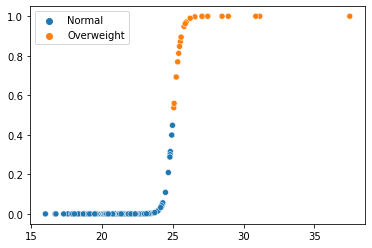

In [41]:
sns.scatterplot(x = X_test[:,0], y = y_prob[:,1], hue = y_test)

Сравним с ситуацией, когда модель вынуждена предсказывать лишний вес только на основе веса респондента

In [42]:
X = df['Weight'].to_numpy().reshape(-1, 1)  
y = df['Obesity_status'].to_numpy()  
X_train, X_test, y_train, y_test = train_test_split(X, y)
clf = LogisticRegression()
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.9171597633136095

<AxesSubplot:>

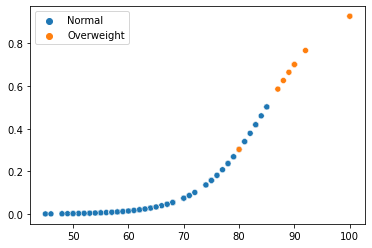

In [43]:
y_prob = clf.predict_proba(X_test)
sns.scatterplot(x = X_test[:,0], y = y_prob[:,1], hue = y_test)

Мы видим, что кривая стала более мягкой, и классы перемешиваются. Модель не может безошибочно классифицировать на основании одного только веса (как не можем и мы). Тем не менее, в целом, чем выше вес, тем больше вероятность, что у человека ожирение. 

Теперь рассмотрим предсказание по двум предикторам одновременно - росту и весу (Пример 2).

In [44]:
X = df[['Weight', 'Height']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)

X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

clf = LogisticRegression()
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.9881656804733728

Модель идеально справилась с этой задачей. 

Чтобы проинтерпретировать коэффициенты модели, найдем их экспоненты: 

In [45]:
for coef in clf.coef_[0]:
    print(np.exp(coef))

9.04173926764993
0.1444205902547165


In [46]:
clf.intercept_

array([169.26773496])

- При увеличении веса на 1 кг шанс того, что у человека лишний вес, увеличивается в 9 раз, при прочих равных условиях 
- При увеличении роста на 1 см шанс того, что у человека лишний вес, уменьшается на 86% 

Метрики качества идеальные 

In [47]:
y_pred = clf.predict(X_test)
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       141
  Overweight       0.96      0.96      0.96        28

    accuracy                           0.99       169
   macro avg       0.98      0.98      0.98       169
weighted avg       0.99      0.99      0.99       169



Теперь посмотрим, сможет ли модель предсказать лишний вес на основе образа жизни (Пример 3). Обратите внимание, что для логистической регрессии номинальные переменные должны быть представлены в формате дамми-переменных (0/1)

In [48]:
X = df[['Internet', 'PC', 'Age', 'Gender_num', 'Edu_num', 'Village_num', 'Spending on healthy eating', 'Spending on looks', 'Happiness in life', 'Health', 'Active sport', 'Adrenaline sports', 'Alco_num', 'Healthy eating', 'Eating to survive', 'Self-criticism']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

clf = LogisticRegression()
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8579881656804734

Выведем коэффициенты для всех переменных 

In [49]:
exp = []
for coef in clf.coef_[0]:
    exp.append(np.exp(coef))

var_list = ['Internet', 'PC', 'Age', 'Gender_num', 'Edu_num', 'Village_num', 'Spending on healthy eating', 'Spending on looks', 'Happiness in life', 'Health', 'Active sport', 'Adrenaline sports', 'Alco_num', 'Healthy eating', 'Eating to survive', 'Self-criticism']
coef_df = pd.DataFrame(exp, index = var_list, columns = ['Coef'])
coef_df.sort_values(by=['Coef'], ascending=False)

,Coef
PC,1.240323
Spending on healthy eating,1.185424
Age,1.132940
Alco_num,1.119070
Eating to survive,1.106786
Happiness in life,1.047058
Spending on looks,1.031871
Adrenaline sports,1.013924
Edu_num,1.000000
Active sport,0.957413


Метрики качества показывают, что модель очень плохо классифицирует людей с лишним весом, хоть и не относит всех в одну категорию

In [50]:
y_pred = clf.predict(X_test)
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       0.86      0.99      0.92       145
  Overweight       0.50      0.04      0.08        24

    accuracy                           0.86       169
   macro avg       0.68      0.52      0.50       169
weighted avg       0.81      0.86      0.80       169



## V. Метод ближайшего соседа (KNN)

KNN в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

Посмотрим, как KNN справится с задачей классификации по росту и весу (Пример 2). Создадим обучающую и тестовую выборки, обучим модель и посмотрим accuracy score для тестовой выборки

In [51]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = df[['Weight', 'Height']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)

X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

# Поскольку KNN использует Евклидово расстояние, перед применением рекомендуется шкалировать переменные 
clf = Pipeline(
    steps=[("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors = 10))]
)
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.9585798816568047

Мы видим, что по сравнению с другими моделями KNN относительно плохо справляется с задачей. Это связано с тем, что рассточние между группами очень маленькое. Если человек имеет BMI 24.8, весьма вероятно, что большинство ближайших соседей будут иметь лишний вес, хотя BMI этого человека является нормальным. 

Визуализируем решение KNN

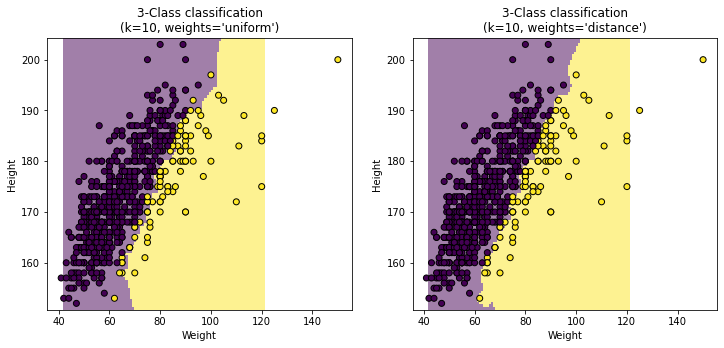

In [52]:
import matplotlib.pyplot as plt

from sklearn.inspection import DecisionBoundaryDisplay

_, axs = plt.subplots(ncols=2, figsize=(12, 5))

for ax, weights in zip(axs, ("uniform", "distance")):
    clf.set_params(knn__weights=weights).fit(X_train, y_train)
    disp = DecisionBoundaryDisplay.from_estimator(
        clf,
        X_test,
        response_method="predict",
        plot_method="pcolormesh",
        xlabel="Weight",
        ylabel="Height",
        shading="auto",
        alpha=0.5,
        ax=ax,
    )
    scatter = disp.ax_.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, edgecolors="k")
    
    _ = disp.ax_.set_title(
        f"3-Class classification\n(k={clf[-1].n_neighbors}, weights={weights!r})"
    )

plt.show()

Метрики качества показывают, что люди с лишним весом иногда попадают в класс людей с нормальным весом, но не наоборот

In [352]:
y_pred = clf.predict(X_test)
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       0.97      1.00      0.99       150
  Overweight       1.00      0.79      0.88        19

    accuracy                           0.98       169
   macro avg       0.99      0.89      0.93       169
weighted avg       0.98      0.98      0.98       169



## VI. Нейронная сеть

Нейронная сеть в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

Посмотрим, как нейронная сеть справится с задачей классификации по росту и весу (Пример 2). Создадим обучающую и тестовую выборки, обучим модель и посмотрим accuracy score для тестовой выборки

In [53]:
from sklearn.neural_network import MLPClassifier
X = df[['Weight', 'Height']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)

X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

clf = MLPClassifier()
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.9053254437869822

По сравнению с другими моделями, нейронная сеть плохо справилась с задачей из Примера 2. Accuracy даже ниже, чем у KNN. Есть ошибки в классификации как людей с нормальным весом, так и людей с лишним весом. 

Нейронные сети не рекомендуется использовать для простых задач

In [356]:
y_pred = clf.predict(X_test)
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       0.95      0.99      0.97       143
  Overweight       0.95      0.73      0.83        26

    accuracy                           0.95       169
   macro avg       0.95      0.86      0.90       169
weighted avg       0.95      0.95      0.95       169



Посмотрим, насколько точно нейросеть сможет предсказать лишний вес по образу жизни (пример 3)

In [54]:
X = df[['Internet', 'PC', 'Age', 'Gender_num', 'Edu_num', 'Village_num', 'Spending on healthy eating', 'Spending on looks', 'Happiness in life', 'Health', 'Active sport', 'Adrenaline sports', 'Alco_num', 'Healthy eating', 'Eating to survive', 'Self-criticism']]
y = df['Obesity_num']
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

clf = MLPClassifier()
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

C:\Users\user\anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:702: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


0.8698224852071006

In [358]:
y_pred = clf.predict(X_test)
print (classification_report(y_test, y_pred, target_names = ['Normal', 'Overweight']))

              precision    recall  f1-score   support

      Normal       0.90      0.98      0.94       150
  Overweight       0.50      0.16      0.24        19

    accuracy                           0.89       169
   macro avg       0.70      0.57      0.59       169
weighted avg       0.86      0.89      0.86       169



С этим заданием нейронная сеть, напротив, справилась лучше, чем все ранее рассмотренные модели

### Выводы

- С предсказанием лишнего веса по росту и весу лучше всего справляются "Метод опорных векторов" и "Логистическая регрессия"
- С предсказанием лишнего веса по образу жизни лучше всего справляется нейронная сеть 

## Самостоятельная работа

Ваша задача: построить модель, которая будет классифицировать людей, которые потребляют много алкоголя, и всех остальных (тех, кто употребляет только иногда или вообще не пьет). 

- Отберите потенциальные предикторы 
- Реализуйте как минимум 3 бинарных классификатора 
- Оцените их качество (Precision, Recall, ROC-AUC)
- Выберете лучшую модель и проинтерпретируйте её

In [ ]:
#start here 